# Exploratory analysis with visualizations

Six charts examine associations among launch sequence, site, payload, orbit and year. Blue marks Class 1 and red marks Class 0. Observational associations are not causal; small orbit groups can yield misleading 100% rates.

In [1]:
%matplotlib inline
"""Reproducible SpaceX capstone: scraping, SQL, visual EDA and model evaluation."""
from pathlib import Path
from io import StringIO
import calendar
import json
import re
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, TimeSeriesSplit, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score, confusion_matrix


ROOT = Path.cwd().parent
DATA = ROOT / 'data'
FIG = ROOT / 'figures'

df = pd.read_csv(DATA/'dataset_part_2.csv',parse_dates=['Date'])
sns.set_theme(style='whitegrid')

## Flight number vs launch site

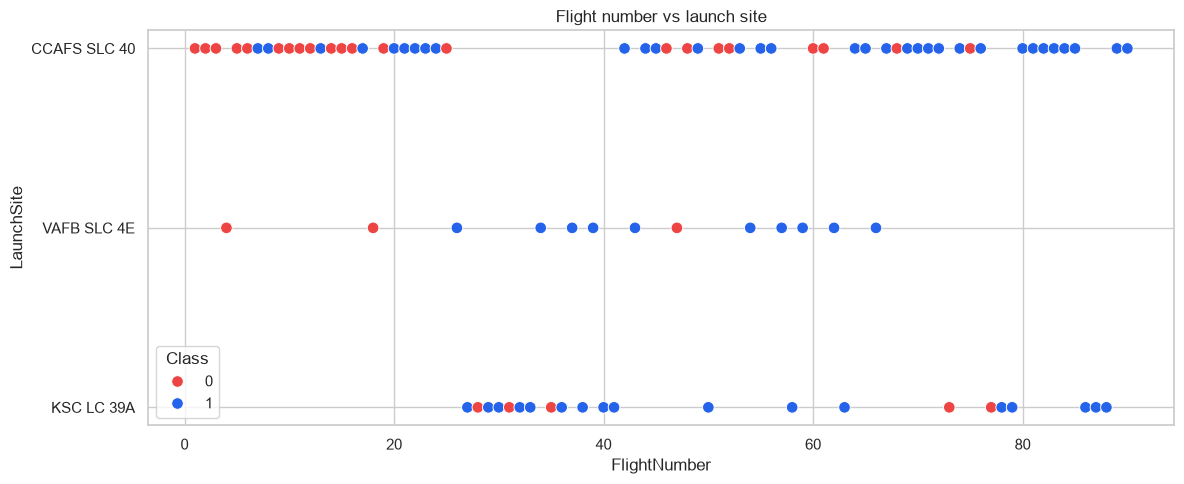

In [2]:
fig, ax = plt.subplots(figsize=(12,5))
sns.scatterplot(data=df,x='FlightNumber',y='LaunchSite',hue='Class',palette={0:'#ef4444',1:'#2563eb'},s=70,ax=ax)
ax.set_title('Flight number vs launch site')
plt.tight_layout()
plt.show()

## Payload vs launch site

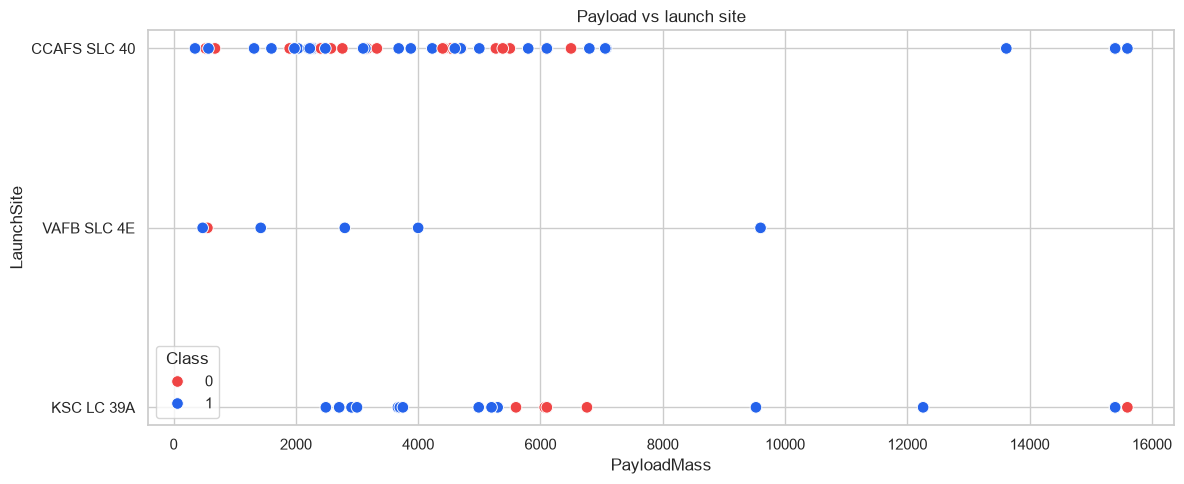

In [3]:
fig, ax = plt.subplots(figsize=(12,5))
sns.scatterplot(data=df,x='PayloadMass',y='LaunchSite',hue='Class',palette={0:'#ef4444',1:'#2563eb'},s=70,ax=ax)
ax.set_title('Payload vs launch site')
plt.tight_layout()
plt.show()

## Flight number vs orbit

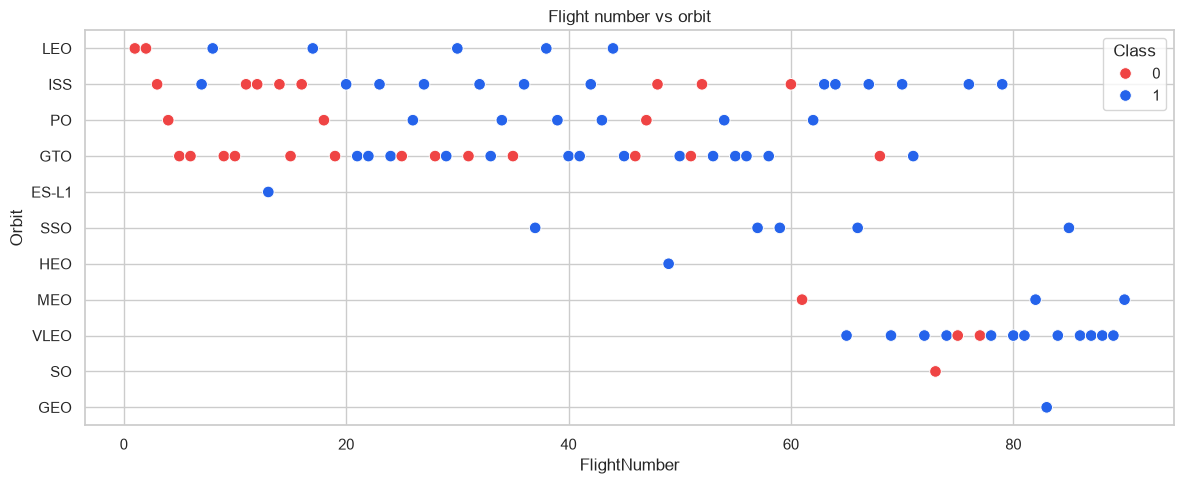

In [4]:
fig, ax = plt.subplots(figsize=(12,5))
sns.scatterplot(data=df,x='FlightNumber',y='Orbit',hue='Class',palette={0:'#ef4444',1:'#2563eb'},s=70,ax=ax)
ax.set_title('Flight number vs orbit')
plt.tight_layout()
plt.show()

## Payload vs orbit

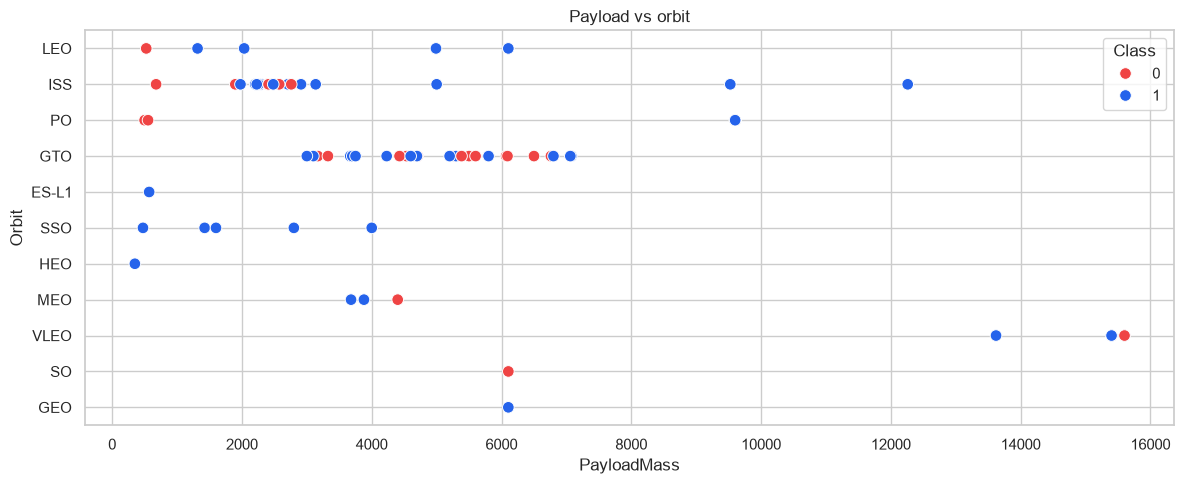

In [5]:
fig, ax = plt.subplots(figsize=(12,5))
sns.scatterplot(data=df,x='PayloadMass',y='Orbit',hue='Class',palette={0:'#ef4444',1:'#2563eb'},s=70,ax=ax)
ax.set_title('Payload vs orbit')
plt.tight_layout()
plt.show()

## Success rate by orbit

,mean,size
Orbit,,
ES-L1,1.000000,1
GEO,1.000000,1
GTO,0.518519,27
HEO,1.000000,1
ISS,0.619048,21
LEO,0.714286,7
MEO,0.666667,3
PO,0.666667,9
SO,0.000000,1


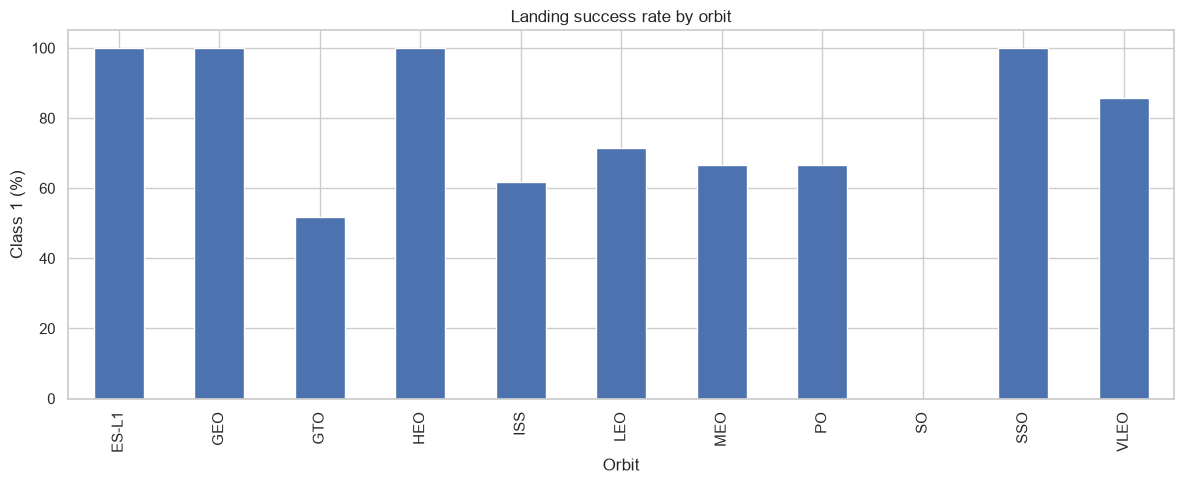

In [6]:
orbit = df.groupby('Orbit').Class.agg(['mean','size'])
display(orbit)
ax = (100*orbit['mean']).plot.bar(figsize=(12,5),title='Landing success rate by orbit',ylabel='Class 1 (%)')
plt.tight_layout()
plt.show()

## Success rate by year

,mean,size
Date,,
2010,0.000000,1
2012,0.000000,1
2013,0.000000,3
2014,0.333333,6
2015,0.333333,6
2016,0.625000,8
2017,0.833333,18
2018,0.611111,18
2019,0.900000,10


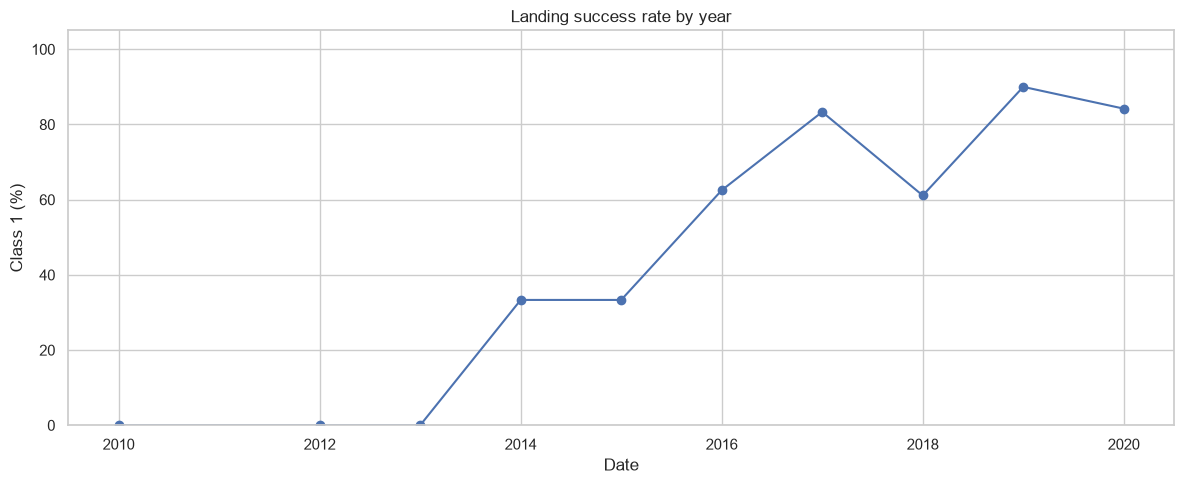

In [7]:
yearly = df.groupby(df.Date.dt.year).Class.agg(['mean','size'])
display(yearly)
(100*yearly['mean']).plot(marker='o',figsize=(12,5),ylim=(0,105),title='Landing success rate by year',ylabel='Class 1 (%)')
plt.tight_layout()
plt.show()